# DS02 · Öğrenme oranı

Derinlik 6’da öğrenme oranını 0,03’ten 0,05’e çıkarmak, eğitimde görülmeyen
motorlarda uçuş sonu RUL hatasını ve eğitim süresini nasıl etkiliyor?

Mevcut tahmin 40 uçuşsa ve yeni ağaç +10 uçuşluk bir düzeltme öğrenmişse, o
adımda 0,03 tahmini 40,3’e, 0,05 ise 40,5’e taşır. Bu, tek bir ağacın katkısıdır.

Ağaç derinliği tek ağacın kaç düzeyde karar verebildiğini, ağaç sayısı kaç
düzeltme eklendiğini, öğrenme oranı ise her düzeltmenin büyüklüğünü belirler.
Farklı oranlar en düşük doğrulama hatasına farklı ağaç sayılarında ulaşabilir.

## Ayarlar ve GPU

Colab’da GPU çalışma zamanını seçin. Varsayılan koşu 0,05’tir. 0,01’i de
denemek için `RUN_001 = True` yapın. Küçük modelin CUDA kullandığı
doğrulanırsa GPU adı yazılır ve deney devam eder.

In [1]:
import hashlib
import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display
from xgboost import XGBRegressor

from io import BytesIO
from tempfile import NamedTemporaryFile
from time import perf_counter

import xgboost

RUN_001 = True
RATES = (0.05, 0.01) if RUN_001 else (0.05,)
MAX_TREES = 3000
EARLY_STOPPING_ROUNDS = 50
model_params = dict(
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    learning_rate=0.03,
    max_depth=6,
    random_state=42,
)



def require_cuda_model(model):
    config = json.loads(model.get_booster().save_config())
    device = config["learner"]["generic_param"]["device"]
    if not device.startswith("cuda"):
        raise RuntimeError(f"XGBoost CPU’ya düştü (cihaz: {device}).")


def check_cuda():
    try:
        x = np.arange(32, dtype=np.float32).reshape(16, 2)
        probe = XGBRegressor(device="cuda", tree_method="hist", n_estimators=1, max_depth=2)
        probe.fit(x, np.arange(16, dtype=np.float32))
        require_cuda_model(probe)
        import cupy as cp

        prediction = probe.get_booster().inplace_predict(cp.asarray(x))
        if not isinstance(prediction, cp.ndarray) or prediction.shape != (len(x),):
            raise RuntimeError("CUDA tahmin kontrolü başarısız.")
        name = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)["name"]
        return cp, name.decode("utf-8") if isinstance(name, bytes) else str(name)
    except Exception as error:
        raise RuntimeError(
            "CUDA doğrulanamadı. Colab’da GPU çalışma zamanını seçin. Uzun eğitim başlatılmadı."
        ) from error


cp, gpu_name = check_cuda()
print(f"GPU doğrulandı: {gpu_name} | XGBoost {xgboost.__version__}", flush=True)

GPU doğrulandı: Tesla T4 | XGBoost 3.4.1


## Drive verisi

V03 ile aynı DS02 dev verisi ve 256/256 metadata’sı kullanılır. CSV eksikse
HDF5 uçuş sınırlarından üretilir. Resmî test verisi okunmaz.

In [2]:
drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive/ncmapss")
h5_path = drive_root / "N-CMAPSS_DS02-006.h5"
metadata_path = drive_root / "ds02_w256_s256" / "window_metadata.csv"
output_dir = drive_root / "deneyler" / "xgboost_v04_ogrenme_orani"

def read_names(dataset):
    return [
        value.decode("utf-8").rstrip("\x00") if isinstance(value, bytes) else str(value)
        for value in np.asarray(dataset[()]).reshape(-1)
    ]


WINDOW_SIZE = 256
STRIDE = 256
FLIGHT_KEYS = ["unit", "cycle"]
META_COLUMNS = ["window_id", *FLIGHT_KEYS, "rul", "start_row", "end_row"]

if not h5_path.is_file():
    raise FileNotFoundError(h5_path)


def read_dev_flights(path):
    with h5py.File(path, "r") as h5:
        id_names = read_names(h5["A_var"])
        if id_names[:2] != FLIGHT_KEYS:
            raise ValueError("DS02 A_dev sütun sırası beklenen unit, cycle ile başlamıyor.")
        identifiers = h5["A_dev"][:, :2].astype(np.int32)
        starts = np.r_[0, np.flatnonzero(np.any(identifiers[1:] != identifiers[:-1], axis=1)) + 1]
        ends = np.r_[starts[1:], len(identifiers)]
        targets = h5["Y_dev"][starts, 0]

    flights = pd.DataFrame(identifiers[starts], columns=FLIGHT_KEYS)
    return flights.assign(start_row=starts, end_row=ends, rul=targets.astype(float))


def build_window_metadata(flights):
    records = []
    for flight in flights.itertuples(index=False):
        for start in range(flight.start_row, flight.end_row - WINDOW_SIZE + 1, STRIDE):
            records.append((len(records), flight.unit, flight.cycle, flight.rul, start, start + WINDOW_SIZE))
    return pd.DataFrame(records, columns=META_COLUMNS)


def validate_generated_metadata(windows, flights):
    if len(flights) != 446 or flights.duplicated(FLIGHT_KEYS).any():
        raise ValueError("HDF5 içinde 446 benzersiz dev uçuşu bekleniyor.")
    if len(windows) != 20_339 or not windows["window_id"].is_unique:
        raise ValueError("20.339 benzersiz pencere bekleniyor.")

    groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    for flight in flights.itertuples(index=False):
        group = groups.pop((flight.unit, flight.cycle))
        count = (flight.end_row - flight.start_row) // WINDOW_SIZE
        starts = flight.start_row + np.arange(count) * STRIDE
        ends = group["end_row"].to_numpy()
        np.testing.assert_array_equal(group["start_row"], starts)
        np.testing.assert_array_equal(ends, starts + WINDOW_SIZE)
        if np.any(ends > flight.end_row):
            raise ValueError(f"Pencere uçuş sınırını aşıyor: {flight.unit}, {flight.cycle}")
    if groups:
        raise ValueError("Metadata içinde HDF5 ile eşleşmeyen uçuş var.")


def load_window_metadata(path, flights):
    if path.is_file():
        print(f"Hazır metadata kullanılıyor: {path}")
        return pd.read_csv(path, dtype={column: "int64" for column in META_COLUMNS if column != "rul"})

    windows = build_window_metadata(flights)
    validate_generated_metadata(windows, flights)
    path.parent.mkdir(parents=True, exist_ok=True)
    windows.to_csv(path, index=False, lineterminator="\r\n")
    print(f"{len(flights)} uçuş ve {len(windows):,} benzersiz pencere doğrulandı. Metadata kaydedildi: {path}")
    return windows


dev_flights = read_dev_flights(h5_path)
metadata = load_window_metadata(metadata_path, dev_flights)

Mounted at /content/drive
Hazır metadata kullanılıyor: /content/drive/MyDrive/ncmapss/ds02_w256_s256/window_metadata.csv


## Pencere girdileri

Her uçuş blok halinde okunur. 18 kanalın ortalaması ve popülasyon standart
sapması alınır. Çıktıda 6 motor, 446 uçuş, 20.339 pencere ve 36 girdi görülür.

In [3]:
assert list(metadata.columns) == META_COLUMNS
assert len(metadata) == 20_339 and metadata["window_id"].is_unique
metadata = metadata.sort_values("window_id", ignore_index=True)


def extract_features(path, windows, flights):
    window_groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    v02_blocks = []
    with h5py.File(path, "r") as h5:
        groups = [(h5[f"{key}_dev"], [f"{key}_{name}" for name in read_names(h5[f"{key}_var"])])
                  for key in ("W", "X_s")]
        feature_columns = [
            f"{name}_{stat}"
            for _, names in groups
            for stat in ("mean", "std")
            for name in names
        ]
        assert [len(names) for _, names in groups] == [4, 14]
        assert len(set(feature_columns)) == 36

        for unit, cycle, start, end, rul in flights.itertuples(index=False, name=None):
            flight_windows = window_groups.pop((unit, cycle)).sort_values("start_row")
            expected_starts = np.arange(start, end - WINDOW_SIZE + 1, WINDOW_SIZE)
            np.testing.assert_array_equal(flight_windows["start_row"], expected_starts)
            np.testing.assert_array_equal(flight_windows["end_row"], expected_starts + WINDOW_SIZE)
            np.testing.assert_allclose(flight_windows["rul"], rul, rtol=0, atol=0)

            window_features = []
            for dataset, names in groups:
                raw = dataset[start:end]
                window_rows = raw[:len(expected_starts) * WINDOW_SIZE].reshape(
                    len(expected_starts), WINDOW_SIZE, len(names)
                )
                window_features.extend([
                    np.mean(window_rows, axis=1, dtype=np.float64),
                    np.std(window_rows, axis=1, dtype=np.float64, ddof=0),
                ])

            stats = pd.DataFrame(np.hstack(window_features), index=flight_windows.index, columns=feature_columns)
            v02_blocks.append(flight_windows.join(stats))

    assert not window_groups
    v02 = pd.concat(v02_blocks).sort_index().rename(columns={"rul": "RUL"})
    return v02, feature_columns


windows, features_36 = extract_features(h5_path, metadata, dev_flights)
actual_flights = (
    dev_flights[[*FLIGHT_KEYS, "rul"]].rename(columns={"rul": "RUL"})
    .sort_values(FLIGHT_KEYS, ignore_index=True)
)
units = sorted(windows["unit"].unique())
assert len(units) == 6 and len(actual_flights) == 446
assert not actual_flights.duplicated(FLIGHT_KEYS).any()
assert len(windows[FLIGHT_KEYS].drop_duplicates()) == 446
assert windows[features_36].shape == (20_339, 36)
print(f"{len(units)} motor, {len(actual_flights)} uçuş, {len(windows):,} pencere, {len(features_36)} girdi")

6 motor, 446 uçuş, 20,339 pencere, 36 girdi


## Eğitim ölçütü

Dış motor değerlendirmeye ayrılır. Diğer beş motor sırayla iç doğrulamaya
alınır. Erken durdurma, pencere medyanlarından hesaplanan uçuş RMSE’sini
izler. Seçilen beş ağaç sayısının medyanı dış modelde kullanılır.
Eğitimde her uçuşun toplam pencere ağırlığı eşittir.

In [4]:
def flight_weights(frame):
    counts = frame.groupby(FLIGHT_KEYS)["RUL"].transform("size")
    weights = 1.0 / counts.to_numpy()
    return weights / weights.mean()




def make_flight_rmse(validation):
    flight_codes = validation.groupby(FLIGHT_KEYS, sort=False).ngroup().to_numpy()
    actual = validation.groupby(FLIGHT_KEYS, sort=False)["RUL"].first().to_numpy()

    def flight_rmse(_window_rul, predictions):
        medians = pd.Series(predictions).groupby(flight_codes, sort=False).median().to_numpy()
        return float(np.sqrt(np.mean(np.square(medians - actual))))

    return flight_rmse




def fit_outer_motor(rate, outer_unit):
    started = perf_counter()
    training = windows.loc[windows["unit"] != outer_unit]
    held_out = windows.loc[windows["unit"] == outer_unit]
    params = {**model_params, "learning_rate": rate, "device": "cuda"}
    inner_results = []
    for number, inner_unit in enumerate(sorted(training["unit"].unique()), start=1):
        label = f"Oran {rate:.2f} | Dış motor {outer_unit} | İç motor {inner_unit} | Tur {number}/5"
        inner_started = perf_counter()
        print(f"{label} | Başladı", flush=True)
        inner_train = training.loc[training["unit"] != inner_unit]
        inner_valid = training.loc[training["unit"] == inner_unit]
        inner_params = {**params, "eval_metric": make_flight_rmse(inner_valid),
                        "disable_default_eval_metric": True}
        model = XGBRegressor(**inner_params, n_estimators=MAX_TREES,
                             early_stopping_rounds=EARLY_STOPPING_ROUNDS)
        model.fit(
            inner_train[features_36], inner_train["RUL"],
            sample_weight=flight_weights(inner_train),
            eval_set=[(inner_valid[features_36], inner_valid["RUL"])],
            verbose=False,
        )
        require_cuda_model(model)
        selected = model.best_iteration + 1
        tried = len(model.evals_result()["validation_0"]["flight_rmse"])
        elapsed = perf_counter() - inner_started
        inner_results.append(dict(unit=int(inner_unit), selected=selected, tried=tried, seconds=elapsed))
        print(f"{label} | Bitti | {selected} ağaç seçildi ({tried} denendi) | {elapsed:.1f} sn", flush=True)

    rounds = int(np.median([item["selected"] for item in inner_results]))
    print(f"Oran {rate:.2f} | Dış motor {outer_unit} | Son eğitim: {rounds} ağaç", flush=True)
    model = XGBRegressor(**params, n_estimators=rounds)
    model.fit(training[features_36], training["RUL"], sample_weight=flight_weights(training))
    require_cuda_model(model)
    flights = held_out[[*FLIGHT_KEYS, "RUL"]].copy()
    gpu_input = cp.asarray(held_out[features_36].to_numpy())
    flights["prediction"] = cp.asnumpy(
        model.get_booster().inplace_predict(gpu_input, validate_features=False)
    )
    flights = flights.groupby(FLIGHT_KEYS, as_index=False).agg(
        RUL=("RUL", "first"), prediction=("prediction", "median")
    )
    return flights, inner_results, rounds, perf_counter() - started

## V03 referansı

0,03 için V03’ün derinlik 6 CSV ve JSON kaydı denetlenir. Ayarlar, girdi
parmak izi, 446 uçuş anahtarı, gerçek RUL ve kayıttan hesaplanan MAE 7,318
ile RMSE 10,162 eşleşmelidir. Kayıt yoksa 0,05 yine çalışır. V03 kayıt
biçiminde cihaz, ağaç sayısı ve süre bulunmayabilir.

In [5]:
input_columns = ["window_id", *FLIGHT_KEYS, "RUL", *features_36]
protocol = {
    "model": "V02-36",
    "split": "DS02-006_dev",
    "window_size": WINDOW_SIZE,
    "stride": STRIDE,
    "input_columns": input_columns,
    "input_sha256": hashlib.sha256(windows[input_columns].to_numpy(dtype="<f8").tobytes()).hexdigest(),
    "outer_units": [int(unit) for unit in units],
    "inner_split": "leave_one_engine_out_within_outer_training",
    "model_params": model_params.copy(),
    "max_trees": MAX_TREES,
    "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
    "selection": "flight_rmse_of_window_medians_then_median_best_rounds",
    "weights": "inverse_windows_per_flight_normalized_to_mean_one",
    "prediction": "flight_median_of_outer_held_out_windows",
}
def raw_metrics(actual, predicted):
    errors = np.asarray(predicted, dtype=float) - np.asarray(actual, dtype=float)
    return np.abs(errors).mean(), np.sqrt(np.square(errors).mean())




def validate_flights(frame, expected):
    columns = [*FLIGHT_KEYS, "RUL"]
    frame = frame[[*columns, "prediction"]].sort_values(FLIGHT_KEYS, ignore_index=True)
    if frame.duplicated(FLIGHT_KEYS).any():
        raise ValueError("Tahmin kaydında tekrar eden uçuş var.")
    pd.testing.assert_frame_equal(frame[columns], expected[columns], check_exact=True, check_dtype=False)
    if not np.isfinite(frame["prediction"].to_numpy(dtype=float)).all():
        raise ValueError("Tahminler sonlu olmalı.")
    return frame


def load_reference(folder):
    path = folder / "derinlik_6_dis_kat_tahminleri.csv"
    try:
        manifest = json.loads(path.with_suffix(".json").read_text(encoding="utf-8"))
        csv_bytes = path.read_bytes()
        recorded = manifest["protocol"].copy()
        params = recorded["model_params"].copy()
        device = params.pop("device", None) or manifest.get("device") or "Bilinmiyor"
        recorded["model_params"] = params
        if recorded != protocol or hashlib.sha256(csv_bytes).hexdigest() != manifest["csv_sha256"]:
            raise ValueError("V03 deney ayarları veya CSV parmak izi eşleşmiyor.")
        saved = pd.read_csv(BytesIO(csv_bytes), float_precision="round_trip")
        frame = validate_flights(saved.rename(columns={"Derinlik 6": "prediction"}), actual_flights)
        observed = tuple(f"{value:.3f}" for value in raw_metrics(frame["RUL"], frame["prediction"]))
        if observed != ("7.318", "10.162"):
            raise ValueError(f"V03 referans metrikleri eşleşmiyor: {observed}")
    except (OSError, ValueError, KeyError, TypeError, AttributeError, AssertionError) as error:
        return None, "Kayıt yok veya doğrulanamadı", f"0,03 V03 derinlik 6 kaydı kullanılamadı: {error}"
    return frame, device, "0,03 V03 derinlik 6 tahminleri doğrulandı."


reference, reference_device, reference_status = load_reference(
    drive_root / "deneyler" / "xgboost_v03_agac_derinligi"
)
print(reference_status, flush=True)

0,03 V03 derinlik 6 tahminleri doğrulandı.


## Eğitim ve devam etme

Her iç turun başlangıcı ve bitişi hemen yazılır. Dış motor bitince tahminler,
ayarlar, ağaç sayıları ve süre tek Drive kaydına yazılır. Bir sonraki
çalıştırmada eksiksiz ve ayarları eşleşen motorlar atlanır. Kayıtlar ilk
koşunun eğitim ve tahmin süresini saklar.

In [6]:
def motor_protocol(rate, unit):
    return {**protocol, "model_params": {**model_params, "learning_rate": rate, "device": "cuda"},
            "outer_unit": int(unit), "xgboost_version": xgboost.__version__}


def motor_expected(unit):
    return actual_flights.loc[actual_flights["unit"] == unit].reset_index(drop=True)


def load_motor(path, rate, unit):
    try:
        record = json.loads(path.read_text(encoding="utf-8"))
        if record["protocol"] != motor_protocol(rate, unit):
            return None
        inner = record["inner"]
        if [item["unit"] for item in inner] != sorted(int(other) for other in units if other != unit):
            return None
        if any(not isinstance(item["selected"], int) or not isinstance(item["tried"], int)
               or not 1 <= item["selected"] <= item["tried"] <= MAX_TREES
               or not np.isfinite(item["seconds"]) or item["seconds"] < 0 for item in inner):
            return None
        if record["rounds"] != int(np.median([item["selected"] for item in inner])):
            return None
        if not np.isfinite(record["seconds"]) or record["seconds"] < sum(item["seconds"] for item in inner):
            return None
        if not isinstance(record["gpu"], str) or not record["gpu"]:
            return None
        flights = validate_flights(pd.DataFrame(record["flights"]), motor_expected(unit))
        return flights, record
    except (OSError, ValueError, TypeError, KeyError, AssertionError):
        return None


def save_motor(path, record):
    path.parent.mkdir(parents=True, exist_ok=True)
    with NamedTemporaryFile(mode="w", encoding="utf-8", dir=path.parent, suffix=".tmp", delete=False) as temporary:
        json.dump(record, temporary, ensure_ascii=False, allow_nan=False)
        temporary_path = Path(temporary.name)
    temporary_path.replace(path)


rate_frames = {}
motor_rows = []
inner_rows = []
for rate in RATES:
    rate_flights = []
    for unit in units:
        path = output_dir / "motor_kayitlari" / f"oran_{rate:.2f}_motor_{unit}.json"
        cached = load_motor(path, rate, unit)
        if cached is None:
            flights, inner, rounds, seconds = fit_outer_motor(rate, unit)
            flights = validate_flights(flights, motor_expected(unit))
            record = dict(protocol=motor_protocol(rate, unit), inner=inner, rounds=rounds,
                          seconds=seconds, gpu=gpu_name, flights=flights.to_dict("records"))
            save_motor(path, record)
            print(f"Oran {rate:.2f} | Dış motor {unit} | Kaydedildi | {seconds:.1f} sn", flush=True)
        else:
            flights, record = cached
            print(f"Oran {rate:.2f} | Dış motor {unit} | Kayıt kullanıldı", flush=True)
        rate_flights.append(flights)
        motor_rows.append({"Oran": rate, "Motor": int(unit), "Cihaz": record["gpu"],
                           "Seçilen ağaç": record["rounds"],
                           "3.000 sınırına ulaşan iç tur": sum(item["tried"] == MAX_TREES for item in record["inner"]),
                           "Süre (sn)": record["seconds"]})
        for item in record["inner"]:
            inner_rows.append({"Oran": rate, "Dış motor": int(unit), "İç motor": item["unit"],
                               "Seçilen ağaç": item["selected"], "Denenen ağaç": item["tried"],
                               "Süre (sn)": item["seconds"]})
    rate_frames[rate] = validate_flights(pd.concat(rate_flights, ignore_index=True), actual_flights)

Oran 0.05 | Dış motor 2 | İç motor 5 | Tur 1/5 | Başladı
Oran 0.05 | Dış motor 2 | İç motor 5 | Tur 1/5 | Bitti | 1051 ağaç seçildi (1101 denendi) | 4.1 sn
Oran 0.05 | Dış motor 2 | İç motor 10 | Tur 2/5 | Başladı
Oran 0.05 | Dış motor 2 | İç motor 10 | Tur 2/5 | Bitti | 649 ağaç seçildi (699 denendi) | 3.0 sn
Oran 0.05 | Dış motor 2 | İç motor 16 | Tur 3/5 | Başladı
Oran 0.05 | Dış motor 2 | İç motor 16 | Tur 3/5 | Bitti | 388 ağaç seçildi (438 denendi) | 2.3 sn
Oran 0.05 | Dış motor 2 | İç motor 18 | Tur 4/5 | Başladı
Oran 0.05 | Dış motor 2 | İç motor 18 | Tur 4/5 | Bitti | 1011 ağaç seçildi (1061 denendi) | 3.8 sn
Oran 0.05 | Dış motor 2 | İç motor 20 | Tur 5/5 | Başladı
Oran 0.05 | Dış motor 2 | İç motor 20 | Tur 5/5 | Bitti | 444 ağaç seçildi (494 denendi) | 1.8 sn
Oran 0.05 | Dış motor 2 | Son eğitim: 649 ağaç
Oran 0.05 | Dış motor 2 | Kaydedildi | 16.5 sn
Oran 0.05 | Dış motor 5 | İç motor 2 | Tur 1/5 | Başladı
Oran 0.05 | Dış motor 5 | İç motor 2 | Tur 1/5 | Bitti | 1333 ağaç 

## Hata, ağaç sayısı ve süre

Hatalar kırpılmamış uçuş tahminlerinden hesaplanır. Genel satırda 446 uçuş
birlikte değerlendirilir. Fark 0,05 − 0,03’tür. Negatif fark hatanın
azaldığını gösterir. Farklı cihazlara ait süre farkı yalnızca öğrenme
oranına bağlanamaz. V03 süre kaydı yoksa süre farkı hesaplanamaz.

In [7]:
available = {0.03: reference, **rate_frames}


def rate_label(rate):
    return f"{rate:.2f}".replace(".", ",")


flight_predictions = actual_flights.copy()
for rate, frame in available.items():
    if frame is not None:
        flight_predictions[rate_label(rate)] = frame["prediction"].to_numpy()

metric_rows = []
for label, flights in [*flight_predictions.groupby("unit"), ("Tümü", flight_predictions)]:
    row = {"Motor": label, "Uçuş sayısı": len(flights)}
    for rate in sorted(available):
        column = rate_label(rate)
        mae, rmse = raw_metrics(flights["RUL"], flights[column]) if column in flights else (np.nan, np.nan)
        row[f"MAE {column}"], row[f"RMSE {column}"] = mae, rmse
    for metric in ("MAE", "RMSE"):
        row[f"{metric} farkı (0.05 − 0.03)"] = row[f"{metric} 0,05"] - row[f"{metric} 0,03"]
    metric_rows.append(row)
metrics = pd.DataFrame(metric_rows)
negative_counts = pd.DataFrame([
    {"Oran": rate, "Negatif tahminli uçuş": int(frame["prediction"].lt(0).sum()) if frame is not None else pd.NA}
    for rate, frame in sorted(available.items())
])
motor_summary = pd.DataFrame(motor_rows)
inner_summary = pd.DataFrame(inner_rows)
timing = motor_summary.groupby("Oran", as_index=False).agg(
    Cihaz=("Cihaz", lambda values: ", ".join(sorted(set(values)))),
    **{"Toplam süre (sn)": ("Süre (sn)", "sum")}
)
timing = pd.concat([pd.DataFrame([{"Oran": 0.03, "Cihaz": reference_device,
                                  "Toplam süre (sn)": np.nan}]), timing], ignore_index=True)
for table in (metrics, negative_counts, motor_summary, inner_summary, timing):
    display(table.round(3))
print(reference_status)

,Motor,Uçuş sayısı,"MAE 0,01","RMSE 0,01","MAE 0,03","RMSE 0,03","MAE 0,05","RMSE 0,05",MAE farkı (0.05 − 0.03),RMSE farkı (0.05 − 0.03)
0,2,75,7.299,8.864,7.238,8.801,7.185,8.761,-0.052,-0.039
1,5,89,9.057,14.331,8.952,14.244,8.876,14.056,-0.077,-0.188
2,10,82,7.353,10.476,6.971,10.085,7.087,10.226,0.116,0.141
3,16,63,7.501,8.870,7.394,8.806,7.420,8.857,0.026,0.050
4,18,71,5.682,7.248,5.486,7.002,5.369,6.943,-0.117,-0.059
5,20,66,7.548,9.120,7.535,9.112,7.432,9.126,-0.103,0.013
6,Tümü,446,7.468,10.304,7.318,10.162,7.285,10.131,-0.033,-0.031


,Oran,Negatif tahminli uçuş
0,0.01,9
1,0.03,11
2,0.05,10


,Oran,Motor,Cihaz,Seçilen ağaç,3.000 sınırına ulaşan iç tur,Süre (sn)
0,0.05,2,Tesla T4,649,0,16.520
1,0.05,5,Tesla T4,806,0,18.965
2,0.05,10,Tesla T4,651,0,14.647
3,0.05,16,Tesla T4,581,0,17.555
4,0.05,18,Tesla T4,707,0,15.647
5,0.05,20,Tesla T4,838,0,22.855
6,0.01,2,Tesla T4,2584,1,51.389
7,0.01,5,Tesla T4,2990,3,54.720
8,0.01,10,Tesla T4,2243,1,44.567
9,0.01,16,Tesla T4,2441,1,49.773


,Oran,Dış motor,İç motor,Seçilen ağaç,Denenen ağaç,Süre (sn)
0,0.05,2,5,1051,1101,4.057
1,0.05,2,10,649,699,3.048
2,0.05,2,16,388,438,2.298
3,0.05,2,18,1011,1061,3.806
4,0.05,2,20,444,494,1.837
5,0.05,5,2,1333,1383,5.532
6,0.05,5,10,1322,1372,5.023
7,0.05,5,16,349,399,1.534
8,0.05,5,18,806,856,3.004
9,0.05,5,20,363,413,1.754


,Oran,Cihaz,Toplam süre (sn)
0,0.03,Bilinmiyor,NaN
1,0.01,Tesla T4,300.284
2,0.05,Tesla T4,106.189


0,03 V03 derinlik 6 tahminleri doğrulandı.


## Motor grafikleri

Gerçek RUL ve kaydı bulunan koşular aynı eksende gösterilir. Negatif
tahminler korunur. Referans eksikse grafikte yalnızca mevcut koşular görünür.

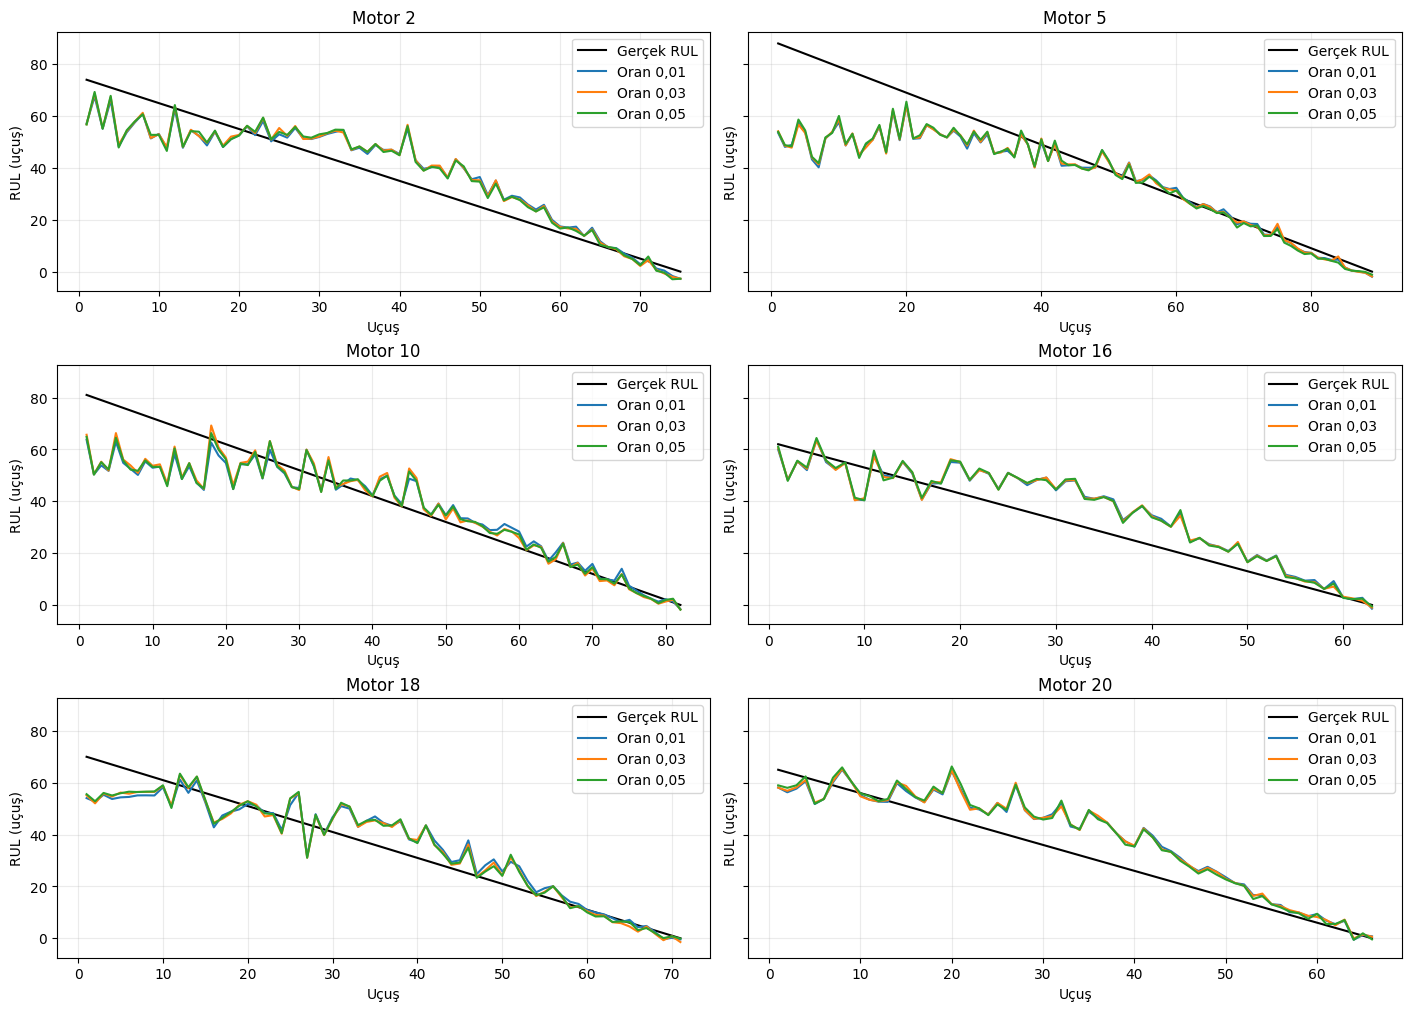

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharey=True, layout="constrained")
for ax, (unit, flights) in zip(axes.flat, flight_predictions.groupby("unit")):
    ax.plot(flights["cycle"], flights["RUL"], color="black", label="Gerçek RUL")
    for rate in sorted(available):
        column = rate_label(rate)
        if column in flights:
            ax.plot(flights["cycle"], flights[column], label=f"Oran {column}")
    ax.set(title=f"Motor {unit}", xlabel="Uçuş", ylabel="RUL (uçuş)")
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## Drive çıktıları

Tahminler, metrikler, grafikler ve süre özetleri V04 klasörüne kaydedilir.
Referansın durumu da aynı klasörde görülebilir.

In [9]:
output_dir.mkdir(parents=True, exist_ok=True)
for name, table in {
    "ucus_tahminleri": flight_predictions, "karsilastirma_metrikleri": metrics,
    "negatif_tahmin_sayilari": negative_counts, "motor_ozeti": motor_summary,
    "ic_tur_ozeti": inner_summary, "sure_ozeti": timing,
}.items():
    table.to_csv(output_dir / f"{name}.csv", index=False, encoding="utf-8-sig")
fig.savefig(output_dir / "motor_tahminleri.png", dpi=150)
(output_dir / "referans_durumu.txt").write_text(reference_status + "\n", encoding="utf-8")
print(output_dir)

/content/drive/MyDrive/ncmapss/deneyler/xgboost_v04_ogrenme_orani


## Sonuç Yorumu

Öğrenme oranını 0,03’ten 0,05’e çıkardığımızda ortalama mutlak hata 0,033 uçuş, RMSE ise 0,031 uçuş azaldı. Bu kazanım küçüktü ve motora göre değişti. Motor 2, 5 ve 18’de her iki hata ölçüsü de düşerken Motor 10 ve 16’da ikisi de yükseldi. Motor 20’de ortalama mutlak hata düştü, ancak RMSE hafifçe yükseldi. Üç öğrenme oranında da en yüksek RMSE’nin Motor 5’te görülmesi, bu motordaki daha büyük tahmin hatalarının sürdüğünü gösterdi.

Eğitim süresindeki fark daha belirgindi. Aynı Tesla T4 üzerinde altı dış turun kayıtlı süreleri toplamı 0,05 için yaklaşık 106 saniye, 0,01 için 300 saniye oldu. 0,05 ile dış motorlar için 581–838 ağaç seçildi ve 30 iç doğrulama turunun hiçbirinde 3.000 ağaç sınırına ulaşılmadı. 0,01 ile 1.934–2.990 ağaç seçildi ve 30 iç turun 9’unda üst sınıra ulaşıldı. Dolayısıyla 0,01 sonucu bu ağaç bütçesi içinde değerlendirilmelidir.

Bu deneyde en düşük genel MAE ve RMSE’yi vermesi ve 0,01 koşusuna göre daha kısa sürede eğitilmesi nedeniyle sonraki XGBoost deneyleri için max_depth=6, learning_rate=0.05 referans ayar olarak seçildi.